# Fit lineare

Adatta una retta alle tue misure, leggi i suoi parametri ed esamina i residui con `mespy.lin_fit()`.

(lf-model)=
## Che cosa fa lin_fit?

`lin_fit()` adatta il modello

$$
y = mx + q
$$

Stima la pendenza $m$, l'intercetta $q$ e le loro incertezze tipo.

**Per impostazione predefinita, il calcolo considera `x` esatto.** Passa le incertezze di misura su `y` tramite `sigma_y`. Per propagare le incertezze su `x`, fornisci `sigma_x` e scegli esplicitamente `x_error_method="iterate"`, come mostrato sotto.

(lf-basic)=
## Fit lineare di base

Salva {download}`linear.csv <data/linear.csv>` nella cartella `data/` del progetto. Contiene misure di esempio della posizione a tempi diversi:

```{literalinclude} data/linear.csv
:language: text
```

- `x`: tempo in secondi, la variabile indipendente.
- `y`: posizione misurata in metri.
- `sigma_y`: l'incertezza tipo di ogni posizione, in metri. I valori devono essere positivi.

Esegui il codice dalla cartella del progetto:

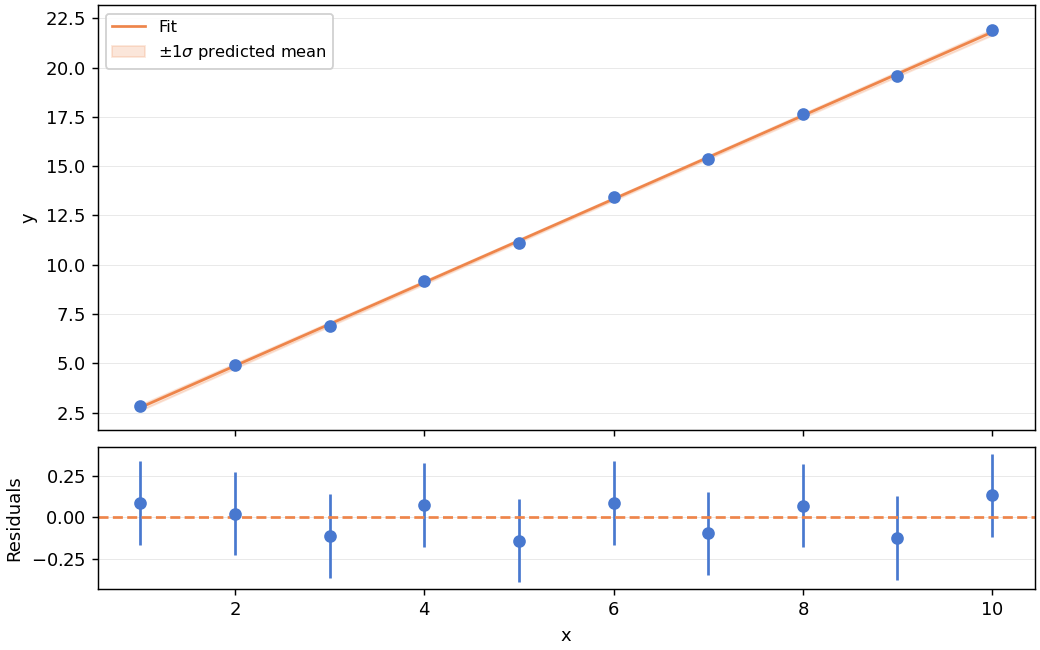

In [1]:
import pandas as pd
from mespy import lin_fit

df = pd.read_csv("data/linear.csv")

result = lin_fit(
    df["x"],
    df["y"],
    sigma_y=df["sigma_y"],
    output="results/linear_fit",
)

Si tratta dei **minimi quadrati pesati (WLS)**: i punti con incertezze minori ricevono un peso maggiore. La funzione restituisce un oggetto `LinearFitResult`, memorizzato come `result`.

`output` imposta la destinazione e il nome base dei file, **senza estensione**. MesPy crea le cartelle mancanti. Con la creazione dei grafici attiva, come avviene per impostazione predefinita, scrive:

```text
results/
├── linear_fit.pdf
└── linear_fit.toml
```

Il **PDF** contiene la figura del fit. Il **TOML** è un file di testo che contiene i dati in ingresso, i parametri del fit, le informazioni diagnostiche disponibili e i residui in unità fisiche.

(lf-results)=
## Interpretare i risultati

(lf-figure)=
### La figura

Il pannello superiore mostra le misure, le loro barre di incertezza tipo e la retta stimata. La banda ombreggiata si estende di **un'incertezza tipo della media prevista** su ciascun lato. Descrive l'incertezza sulla retta, anziché un intervallo che ci si aspetta contenga misure future.

Il pannello inferiore mostra i residui:

$$
r_i = y_i - (mx_i + q)
$$

Un residuo è la distanza verticale di una misura dalla retta. I valori positivi si trovano sopra la retta; quelli negativi sotto. Cerca una dispersione attorno a zero. Un andamento curvo, per esempio, può suggerire che una retta non descriva una tendenza dei dati.

I residui **non sono normalizzati per impostazione predefinita**: mantengono le unità di `y`. Leggili tramite `result.residuals`; accedi alla figura Matplotlib tramite `result.figure`.

(lf-numbers)=
### I risultati numerici

Leggi gli attributi principali:

In [2]:
print(f"Slope: {result.slope:.3f} +/- {result.slope_std:.3f}")
print(f"Intercept: {result.intercept:.3f} +/- {result.intercept_std:.3f}")
print(f"Chi-squared: {result.chi2:.3f}")
print(f"Reduced chi-squared: {result.reduced_chi2:.3f}")
print(f"p-value: {result.p_value:.3f}")
print(f"Degrees of freedom: {result.dof}")
print("Fit method:", result.fit_method)
print("x uncertainty treatment:", result.x_error_method)

Slope: 2.114 +/- 0.028
Intercept: 0.650 +/- 0.171
Chi-squared: 1.598
Reduced chi-squared: 0.200
p-value: 0.991
Degrees of freedom: 8
Fit method: wls
x uncertainty treatment: none


| Attributo | Significato |
| --- | --- |
| `slope`, `slope_std` | Pendenza $m$ e sua incertezza tipo; qui entrambe hanno unità m/s. |
| `intercept`, `intercept_std` | Posizione $q$ a $x=0$ e sua incertezza tipo, in metri. |
| `chi2` | Somma dei quadrati dei residui divisi per le rispettive varianze. |
| `reduced_chi2` | `chi2 / dof`, quando `dof` è positivo. |
| `p_value` | Sotto le ipotesi sul modello e sugli errori, la probabilità di un chi quadro almeno pari a quello osservato. |
| `dof` | Numero di misure meno i due parametri stimati. |
| `fit_method` | `"wls"` con `sigma_y`, oppure `"ols"` senza. |
| `x_error_method` | `"none"` o `"iterate"`: come entrano nel calcolo le incertezze orizzontali. |

**Le incertezze dei parametri differiscono dalle incertezze di misura.** `slope_std` e `intercept_std` descrivono con quale precisione è determinata la retta. `sigma_y` descrive le singole misure. WLS usa le incertezze assolute fornite senza riscalare le incertezze dei parametri mediante il chi quadro ridotto.

L'interpretazione del chi quadro e del valore p presuppone errori di misura gaussiani indipendenti, incertezze attendibili e un modello appropriato. Un chi quadro ridotto vicino a uno è compatibile con la dispersione ipotizzata. Valori grandi possono suggerire un modello inadeguato o incertezze sottostimate; valori molto piccoli possono suggerire incertezze sovrastimate. Un valore p **non è la probabilità che il modello sia corretto**. Esamina anche i residui.

Con soli due punti pesati, `dof=0`: `chi2` è disponibile, ma `residual_std`, `reduced_chi2` e `p_value` sono `None`.

`result.residual_std` descrive la dispersione dei residui nelle unità di `y`, usando `dof` al denominatore della varianza. In WLS ha un significato descrittivo e `result.estimated_sigma` è `None`.

(lf-x-errors)=
## Incertezze su x

Supponi che ogni misura del tempo abbia anche un'incertezza tipo di **0.05 secondi**. `sigma_x` accetta questo singolo valore oppure un valore per misura. I valori devono essere finiti e non negativi; zero indica l'assenza di incertezza orizzontale.

| `x_error_method` | Effetto di `sigma_x` |
| --- | --- |
| `"none"` (predefinito) | Disegna barre orizzontali; mantiene il calcolo OLS/WLS esistente. |
| `"iterate"` | Propaga le incertezze orizzontali mediante ripesatura iterativa; richiede sia `sigma_x` sia `sigma_y`. |

(lf-x-bars)=
### Mostra le barre orizzontali

Scegli `"none"` per mostrare le incertezze senza includerle nel calcolo:

In [3]:
bars_only = lin_fit(
    df["x"],
    df["y"],
    sigma_y=df["sigma_y"],
    sigma_x=0.05,
    x_error_method="none",
    output="results/horizontal_bars",
)

Le barre orizzontali compaiono in entrambi i pannelli. I parametri stimati, le loro incertezze e le informazioni diagnostiche rimangono gli stessi dell'esempio di base.

(lf-x-iterate)=
### Propaga le incertezze orizzontali

Seleziona `"iterate"` per includere `sigma_x` nel calcolo:

In [4]:
result_with_x = lin_fit(
    df["x"],
    df["y"],
    sigma_y=df["sigma_y"],
    sigma_x=0.05,
    x_error_method="iterate",
    output="results/linear_fit_x",
)

Qui ogni punto ha lo stesso `sigma_y` e lo stesso `sigma_x`. La propagazione lascia quindi invariate pendenza e intercetta, ma aumenta le loro incertezze tipo. Confronta l'incertezza della pendenza:

In [5]:
print(f"Without propagation: {bars_only.slope_std:.3f} m/s")
print(f"With propagation: {result_with_x.slope_std:.3f} m/s")

Without propagation: 0.028 m/s
With propagation: 0.030 m/s


MesPy parte dal fit con sole incertezze su y, poi aggiorna ripetutamente le varianze efficaci:

$$
\sigma_{\mathrm{eff},i}^{2} = \sigma_{y_i}^{2} + m^{2}\sigma_{x_i}^{2}
$$

Ripete il fit usando queste varianze finché la variazione relativa della pendenza è al massimo `1e-10`. Se non converge entro 100 iterazioni, solleva `RuntimeError` prima di creare figure o file.

Si tratta di un **metodo iterativo approssimato**. La covarianza dei parametri, la banda di incertezza e il valore p del chi quadro hanno un'interpretazione approssimata. La convergenza non garantisce un minimo del criterio efficace.

`result_with_x.fit_method` rimane `"wls"`; `result_with_x.x_error_method` è `"iterate"`. I file sono `linear_fit_x.pdf` e `linear_fit_x.toml`.

Quando viene fornito `sigma_x`, il TOML usa lo schema 3 e conserva i suoi valori originali e l'`x_error_method` selezionato, compreso `"none"`. Le chiamate senza `sigma_x` mantengono lo schema 2.

(lf-unweighted)=
## Che cosa succede se sigma_y non viene fornito?

In [6]:
unweighted_result = lin_fit(
    df["x"],
    df["y"],
    output="results/unweighted_fit",
)

MesPy esegue i **minimi quadrati ordinari (OLS)**: tutte le osservazioni ricevono lo stesso peso. Emette un `UserWarning` e stima una dispersione verticale comune dai residui.

- `unweighted_result.fit_method` è `"ols"`. `fit_method` è un attributo del risultato, non un argomento della funzione.
- `unweighted_result.estimated_sigma` è uguale a `unweighted_result.residual_std`. Questa stima fornisce le incertezze dei parametri. OLS richiede almeno tre misure.
- Pendenza, intercetta, le loro incertezze, i residui e `dof` rimangono disponibili.
- `chi2`, `reduced_chi2` e `p_value` sono `None` e vengono omessi dal TOML.

Senza `sigma_x`, la figura non ha barre di incertezza di misura. Puoi fornire `sigma_x` per le barre orizzontali con `x_error_method="none"`; la propagazione con `"iterate"` richiede anche `sigma_y`.

**Omettere `sigma_y` non equivale a impostare `sigma_y=1`.** Quest'ultimo dichiara un'incertezza tipo nota di un'unità di `y` per misura. Assegna pesi uguali, ma usa le incertezze dei parametri e le informazioni diagnostiche WLS, anche quando la retta stimata è la stessa.

Fornisci le incertezze di misura quando sono disponibili e scientificamente giustificate.

(lf-normalized)=
## Residui normalizzati

Il valore predefinito è **`normalize_residuals=False`**. Richiedi esplicitamente la normalizzazione:

In [7]:
normalized_result = lin_fit(
    df["x"],
    df["y"],
    sigma_y=df["sigma_y"],
    normalize_residuals=True,
    output="results/normalized_fit",
)

Per questo fit pesato con sole incertezze su y, il pannello inferiore mostra

$$
r_i^{\mathrm{norm}} = \frac{y_i - (mx_i + q)}{\sigma_{y_i}}
$$

Questi valori adimensionali esprimono gli scarti in unità dell'incertezza tipo di ogni misura, rendendo più semplice confrontare misure con incertezze diverse.

Il denominatore dipende dal fit selezionato:

| Fit | Dividi i residui in unità fisiche per |
| --- | --- |
| WLS con `x_error_method="none"` | Il `sigma_y` fornito. |
| WLS con `x_error_method="iterate"` | L'incertezza efficace finale `sqrt(sigma_y**2 + slope**2 * sigma_x**2)`. |
| OLS | La dispersione comune `estimated_sigma`, stimata dagli stessi residui. |

Per normalizzare il fit iterativo, includi anche `sigma_x=0.05` e `x_error_method="iterate"` nella chiamata sopra. In entrambe le modalità WLS, le barre di incertezza verticali mostrate hanno allora una semilunghezza pari a uno. Le barre orizzontali mantengono le unità originali di `x`.

La normalizzazione OLS non fornisce incertezze di misura note né informazioni diagnostiche basate sul chi quadro. Una dispersione OLS nulla non può essere normalizzata per la rappresentazione grafica e solleva `ValueError`.

**La normalizzazione modifica soltanto la visualizzazione dei residui.** Non cambia i parametri stimati, le loro incertezze o il metodo. `normalized_result.residuals` e i residui salvati in TOML rimangono sempre in unità fisiche.

(lf-related)=
## Pagine correlate

- [Flusso di lavoro di base](basic-workflow.ipynb)
- [Stile dei grafici](plot-style.ipynb)
- [Riferimento API di `lin_fit`](../moduli/fit_utils/lin-fit.md)